In [1]:
!pip -q install ultralytics faiss-cpu kaggle scikit-learn

import os, random, glob, urllib.parse, numpy as np, torch, torch.nn as nn, faiss
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report
from ultralytics import YOLO

device = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(42); np.random.seed(42); torch.manual_seed(42)
print("Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 6.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Device: cuda


In [2]:
from google.colab import files
files.upload()   # upload kaggle.json

!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d robinreni/house-rooms-image-dataset -p data --unzip -q

Saving archive (9).zip to archive (9).zip
cp: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/robinreni/house-rooms-image-dataset
License(s): CC0-1.0


In [3]:
IMG_EXT = (".jpg", ".jpeg", ".png")

def find_root(base):
    """Find the folder that directly contains the class sub-folders."""
    for r, dirs, _ in os.walk(base):
        cls = [d for d in dirs if any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(r, d)))]
        if len(cls) >= 4:
            return r
    raise RuntimeError("Could not find class folders")

ROOT = find_root("data")
print("Dataset root:", ROOT)

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
                               transforms.ColorJitter(0.2, 0.2, 0.2), transforms.ToTensor(),
                               transforms.Normalize(mean, std)])
val_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(mean, std)])

full_train = datasets.ImageFolder(ROOT, transform=train_tf)
full_val   = datasets.ImageFolder(ROOT, transform=val_tf)
classes = full_train.classes
print("Classes:", classes, "| Total images:", len(full_train))

idx = np.random.permutation(len(full_train)); cut = int(0.8 * len(idx))
train_ds, val_ds = Subset(full_train, idx[:cut]), Subset(full_val, idx[cut:])
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds, batch_size=64, num_workers=2)

Dataset root: data/House_Room_Dataset
Classes: ['Bathroom', 'Bedroom', 'Dinning', 'Kitchen', 'Livingroom'] | Total images: 5250


In [4]:
def build(name, n):
    if name == "resnet50":
        m = models.resnet50(weights="IMAGENET1K_V2"); m.fc = nn.Linear(2048, n)
    elif name == "vgg16":
        m = models.vgg16(weights="IMAGENET1K_V1"); m.classifier[6] = nn.Linear(4096, n)
    elif name == "vit":
        m = models.vit_b_16(weights="IMAGENET1K_V1"); m.heads.head = nn.Linear(768, n)
    return m.to(device)

LR = {"resnet50": 1e-4, "vgg16": 1e-5, "vit": 3e-5}
EPOCHS = 5
os.makedirs("weights", exist_ok=True)

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); preds, labels = [], []
    for x, y in dl:
        with torch.autocast(device, enabled=device == "cuda"):
            out = model(x.to(device))
        preds += out.argmax(1).cpu().tolist(); labels += y.tolist()
    return np.mean(np.array(preds) == np.array(labels)), labels, preds

def train(name):
    model = build(name, len(classes))
    opt = torch.optim.AdamW(model.parameters(), lr=LR[name], weight_decay=1e-4)
    scaler = torch.amp.GradScaler(device, enabled=device == "cuda")
    crit, best = nn.CrossEntropyLoss(), 0
    for ep in range(EPOCHS):
        model.train(); tot = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.autocast(device, enabled=device == "cuda"):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        acc, _, _ = evaluate(model, val_dl)
        print(f"[{name}] epoch {ep+1}/{EPOCHS}  loss={tot/len(train_dl):.4f}  val_acc={acc:.4f}")
        if acc > best:
            best = acc; torch.save(model.state_dict(), f"weights/{name}.pt")
    return best

results = {n: train(n) for n in ["resnet50", "vgg16", "vit"]}
print("\nValidation accuracy:", {k: round(v, 4) for k, v in results.items()})

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 72.2MB/s]


[resnet50] epoch 1/5  loss=0.7466  val_acc=0.8590
[resnet50] epoch 2/5  loss=0.2400  val_acc=0.8895
[resnet50] epoch 3/5  loss=0.1119  val_acc=0.8838
[resnet50] epoch 4/5  loss=0.0764  val_acc=0.8905
[resnet50] epoch 5/5  loss=0.0545  val_acc=0.8800
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 166MB/s]


[vgg16] epoch 1/5  loss=1.0393  val_acc=0.8010
[vgg16] epoch 2/5  loss=0.5059  val_acc=0.8371
[vgg16] epoch 3/5  loss=0.3635  val_acc=0.8619
[vgg16] epoch 4/5  loss=0.2633  val_acc=0.8648
[vgg16] epoch 5/5  loss=0.2151  val_acc=0.8724
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 89.2MB/s]


[vit] epoch 1/5  loss=0.4982  val_acc=0.8829
[vit] epoch 2/5  loss=0.1636  val_acc=0.9038
[vit] epoch 3/5  loss=0.0888  val_acc=0.8971
[vit] epoch 4/5  loss=0.0478  val_acc=0.8810
[vit] epoch 5/5  loss=0.0424  val_acc=0.8838

Validation accuracy: {'resnet50': np.float64(0.8905), 'vgg16': np.float64(0.8724), 'vit': np.float64(0.9038)}


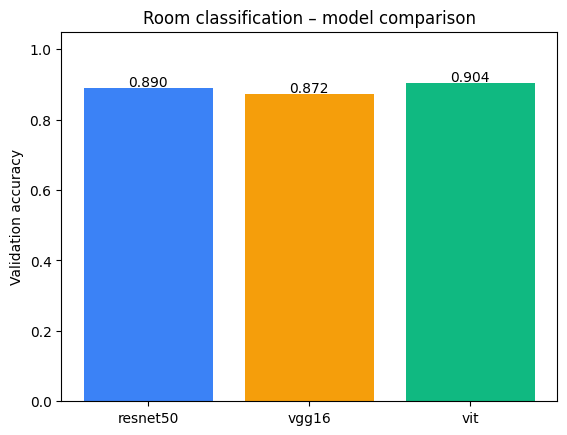

Using classifier: vit
              precision    recall  f1-score   support

    Bathroom       0.93      0.95      0.94       101
     Bedroom       0.94      0.95      0.95       240
     Dinning       0.86      0.90      0.88       246
     Kitchen       0.91      0.85      0.88       203
  Livingroom       0.89      0.88      0.89       260

    accuracy                           0.90      1050
   macro avg       0.91      0.91      0.91      1050
weighted avg       0.90      0.90      0.90      1050



In [5]:
plt.bar(results.keys(), results.values(), color=["#3b82f6", "#f59e0b", "#10b981"])
plt.ylabel("Validation accuracy"); plt.title("Room classification – model comparison")
for i, v in enumerate(results.values()): plt.text(i, v + 0.005, f"{v:.3f}", ha="center")
plt.ylim(0, 1.05); plt.show()

# Choose classifier. Set CLASSIFIER = "resnet50" to force ResNet50 as in your project description.
CLASSIFIER = max(results, key=results.get)
print("Using classifier:", CLASSIFIER)

clf = build(CLASSIFIER, len(classes)); clf.load_state_dict(torch.load(f"weights/{CLASSIFIER}.pt")); clf.eval()
_, y_true, y_pred = evaluate(clf, val_dl)
print(classification_report(y_true, y_pred, target_names=classes))

In [6]:
yolo = YOLO("yolov8m.pt")

FURNITURE = {"chair": "chair", "couch": "sofa", "bed": "bed", "dining table": "dining table",
             "tv": "tv unit", "potted plant": "indoor plant", "toilet": "toilet", "sink": "sink",
             "refrigerator": "refrigerator", "oven": "oven", "microwave": "microwave",
             "vase": "decor vase", "clock": "wall clock", "bench": "bench"}

def detect(img, conf=0.35, min_size=60):
    """Returns list of dicts: label, conf, box, crop."""
    res = yolo.predict(img, conf=conf, verbose=False)[0]
    out = []
    for b in res.boxes:
        label = res.names[int(b.cls)]
        if label not in FURNITURE: continue
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        if (x2 - x1) < min_size or (y2 - y1) < min_size: continue
        out.append({"label": label, "conf": float(b.conf), "box": (x1, y1, x2, y2), "crop": img.crop((x1, y1, x2, y2))})
    return out

In [7]:
# Generic visual embedding: ImageNet ResNet50 without classifier head
emb_net = models.resnet50(weights="IMAGENET1K_V2"); emb_net.fc = nn.Identity(); emb_net = emb_net.to(device).eval()

@torch.no_grad()
def embed(pil_list, bs=64):
    feats = []
    for i in range(0, len(pil_list), bs):
        x = torch.stack([val_tf(im) for im in pil_list[i:i+bs]]).to(device)
        f = emb_net(x).cpu().numpy().astype("float32")
        feats.append(f)
    f = np.vstack(feats); faiss.normalize_L2(f); return f     # cosine similarity via inner product

def shop_link(label, room):
    return "https://www.amazon.in/s?k=" + urllib.parse.quote_plus(f"{FURNITURE[label]} for {room}")

# ---- 5a. Room-level indexes (one per room type) ----
room_paths = {c: [] for c in classes}
for p, y in full_val.samples:
    room_paths[classes[y]].append(p)

room_index = {}
for c, paths in room_paths.items():
    paths = paths[:600]
    idx_ = faiss.IndexFlatIP(2048)
    idx_.add(embed([Image.open(p).convert("RGB") for p in paths]))
    room_index[c] = (idx_, paths)
print("Room indexes built:", {c: v[0].ntotal for c, v in room_index.items()})

# ---- 5b. Furniture-level indexes (one per furniture type) from detected crops ----
os.makedirs("catalog", exist_ok=True)
CATALOG_IMAGES = 800                                   # increase for a bigger catalog
sample_imgs = random.sample(full_val.samples, min(CATALOG_IMAGES, len(full_val.samples)))
crops, meta = [], []
for p, y in sample_imgs:
    im = Image.open(p).convert("RGB")
    for d in detect(im):
        fp = f"catalog/{len(meta)}.jpg"; d["crop"].save(fp)
        crops.append(d["crop"]); meta.append({"label": d["label"], "room": classes[y], "file": fp})
print("Catalog items:", len(meta))

feats = embed(crops)
furn_index = {}
for lab in FURNITURE:
    ids = [i for i, m in enumerate(meta) if m["label"] == lab]
    if not ids: continue
    ix = faiss.IndexFlatIP(2048); ix.add(feats[ids])
    furn_index[lab] = (ix, [meta[i] for i in ids])
print({k: v[0].ntotal for k, v in furn_index.items()})

Room indexes built: {'Bathroom': 600, 'Bedroom': 600, 'Dinning': 600, 'Kitchen': 600, 'Livingroom': 600}
Catalog items: 643
{'chair': 139, 'couch': 142, 'bed': 163, 'dining table': 148, 'tv': 2, 'potted plant': 13, 'toilet': 11, 'sink': 7, 'refrigerator': 12, 'oven': 5, 'bench': 1}


In [8]:
@torch.no_grad()
def predict_room(img):
    x = val_tf(img).unsqueeze(0).to(device)
    p = torch.softmax(clf(x), 1)[0]
    i = int(p.argmax()); return classes[i], float(p[i])

def show_row(images, titles, suptitle):
    fig, axs = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
    axs = np.atleast_1d(axs)
    for a, im, t in zip(axs, images, titles):
        a.imshow(im); a.set_title(t, fontsize=9); a.axis("off")
    fig.suptitle(suptitle, fontsize=13); plt.show()

def recommend(img_path, k_rooms=4, k_items=3):
    img = Image.open(img_path).convert("RGB")

    # 1) Classify room
    room, p = predict_room(img)
    print(f"\n🏠 Predicted room type: {room}  ({p:.1%} confidence)")

    # 2) Detect furniture
    dets = detect(img)
    print("🪑 Detected:", [d["label"] for d in dets] or "nothing")
    ann = yolo.predict(img, conf=0.35, verbose=False)[0].plot()[..., ::-1]
    show_row([img, ann], ["Input", "YOLOv8 detections"], "Analysis")

    # 3) Similar room interiors (FAISS)
    ix, paths = room_index[room]
    D, I = ix.search(embed([img]), k_rooms)
    show_row([Image.open(paths[i]) for i in I[0]], [f"sim={d:.2f}" for d in D[0]],
             f"Similar {room} interiors for inspiration")

    # 4) Similar furniture + shopping links (FAISS)
    seen = set()
    for d in dets:
        lab = d["label"]
        if lab in seen or lab not in furn_index: continue
        seen.add(lab)
        ix, items = furn_index[lab]
        D, I = ix.search(embed([d["crop"]]), min(k_items, ix.ntotal))
        show_row([Image.open(items[i]["file"]) for i in I[0]], [f"sim={s:.2f}" for s in D[0]],
                 f"Similar {FURNITURE[lab]}s")
        print(f"🛒 Buy {FURNITURE[lab]}: {shop_link(lab, room)}")


🏠 Predicted room type: Bedroom  (99.9% confidence)
🪑 Detected: ['bed']


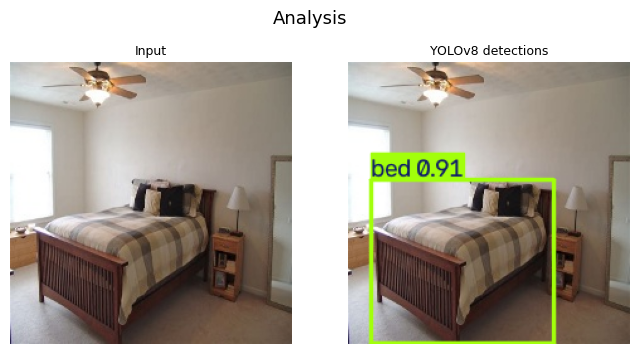

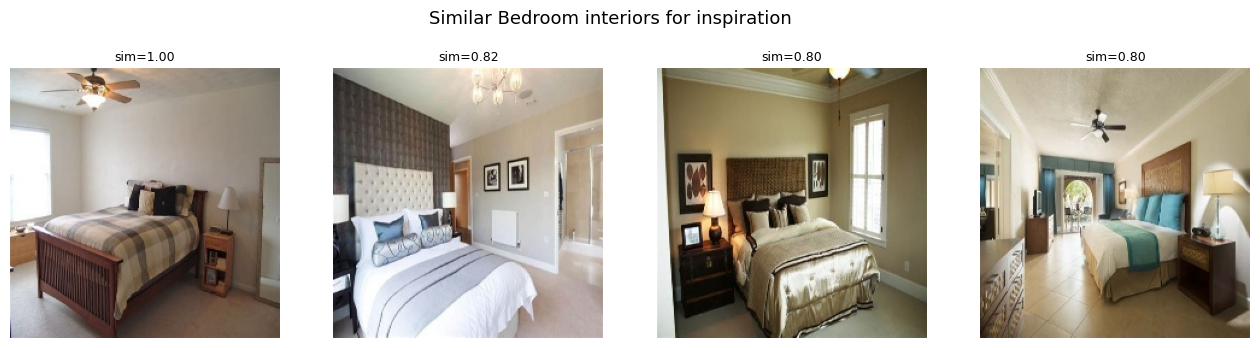

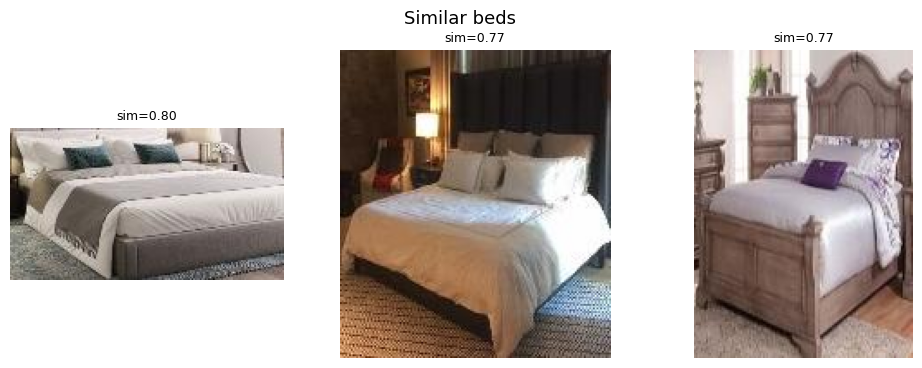

🛒 Buy bed: https://www.amazon.in/s?k=bed+for+Bedroom


In [9]:
recommend(random.choice(full_val.samples)[0])

Saving WhatsApp Image 2026-09-30 at 7.49.16 PM.jpeg to WhatsApp Image 2026-09-30 at 7.49.16 PM.jpeg

🏠 Predicted room type: Livingroom  (51.2% confidence)
🪑 Detected: ['chair', 'bed']


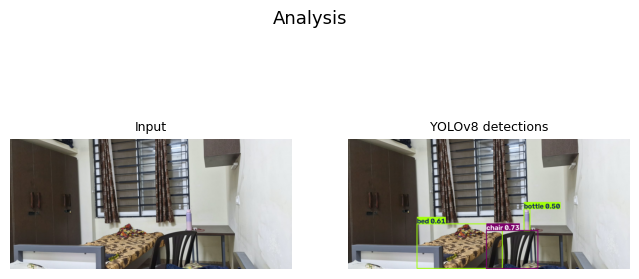

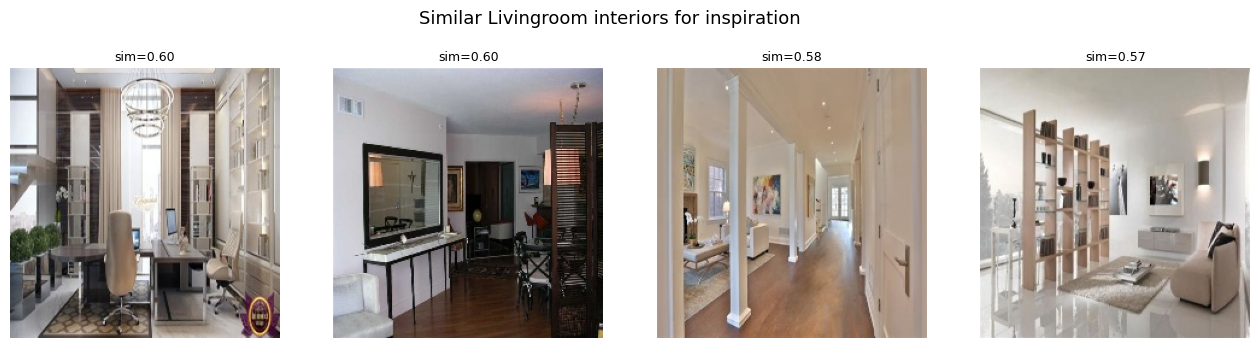

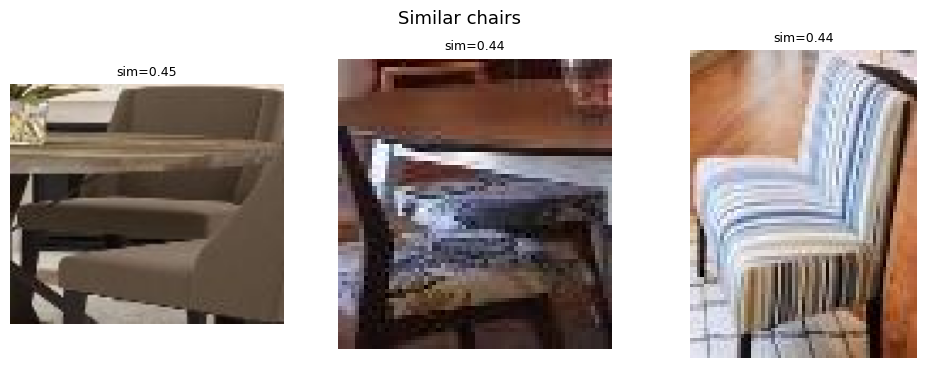

🛒 Buy chair: https://www.amazon.in/s?k=chair+for+Livingroom


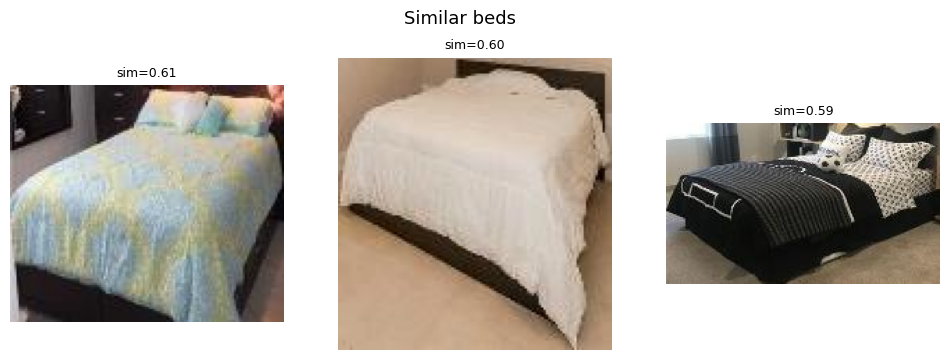

🛒 Buy bed: https://www.amazon.in/s?k=bed+for+Livingroom


In [10]:
up = files.upload()
for fn in up: recommend(fn)